# Day 06 - Quantum Error correction Technique : Exact CSS(CalderBank-Shor-Steane) code
The calderbank-Shore-Steane(CSS) construction is the quantum error correction framework that combines classical error correcting code to detect quantum bit-flip and pahse-flip errors.

Unlike studying Bit-flip and phase-flip  codes seperatly ,CSS code used two compatible sets of stabilizers to identify the different types of quantum error withoin unified framework.In this notebook we will studied:
- Understand CSS construction and Stabilizer representation 
- distingished bit-flip and phase-flip syndrome
- Implemets CSS stabilizers CSS code with Qiskit
- Simulates control X,Y and Z errors
- Measure stabilizer syndromeand visualize error detection.

#### Implemetation Scope:
This notebook implemets the four qubit CSS-code with satbilizers XXX and ZZZ.This is the [[4,2,2]]  code which detects arbitary single qubit pauli errors does not correct arbitary single qubit errors.

This is Distinct CSS construction .Not other implemenation of Stean or Shore code.



## Introduction of CSS code
Quantum state are vulnarable to bit-flip error(X),phase flip errors(Z) and both bota nd pahse flip errors(Y).the css construction organizes errors  detection using two compatible stabilizers family:
- **X-type stabilizers** : products of x-operators
- **Z-type satbilizers** : products of z-operators
 A stabilizers measurement reaveals information about an error without  directly measuring  the encoded logical information.
 for this notebook,we use fou data qubits and the stabilizers:
 - $S_X= XXXX$
 - $S_Z= ZZZZ$
 Both stabilizers commutesbecause they overlap on four qubits,an even number .thier simulations + eigenvalues defines a [[4,2,2]] CSS code.

 ### Mathematical background
 A stabilizers S has eigenvalues +1 for an ideal code state. An error that anticommute with S changes the measured eigenvalue to -1. for single qubit pauli errors:
 - X anticommute with Z ,so an X error changes the Z-type syndrome.
 - Z anticommute with X ,so an X error changes the X-type syndrome.
 - Y anticommute with both X and Z ,so it changes the both syndrome.


 The stabilizers syndrome is represented by two binary values:$s_Xs_Z$

 here 0 denotes eigenvalues +1 and 1 denotes eigenvlaue -1.

 **Important limitation** :
 the [[4,2,2]] code detects any single qubit puali errors ,bute its syndrome does not uniquly identify the every possible error location ,Detection and correction are different capabilities.

## Imprt Required Libraries

In [1]:
from qiskit import QuantumCircuit,QuantumRegister,ClassicalRegister
from qiskit_aer import AerSimulator
import numpy as np
import matplotlib.pyplot as plt
simulator=AerSimulator()
SHOTS=4096
print("Qiskit CSS-code simulations initialized")

Qiskit CSS-code simulations initialized


## Prepare CSS Code State
We prepare the four-qubit state
$$|\psi\rangle= \frac{|0000\rangle + |1111\rangle}{\sqrt{2}}$$

A hadamard gate creates a superposition on the first data qubits and three CNOT gates distributed that superposition accross the register.This state is a +1 eigenstate of both XXXX and ZZZZ ,making it suitable for demonstrating CSS stabilizers measurement.
The four data qubits are used for code State .two additional ancilla qubits will extract the stabilizers syndrome.

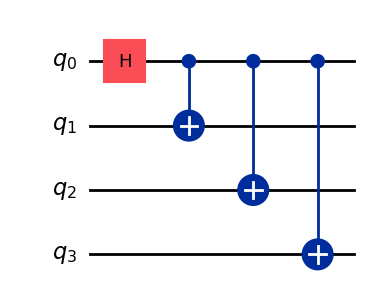

In [2]:
def prepare_css_state(qc,data):
    # prepare the four qubit CSS code state
    qc.h(data[0])
    for i in range(1,4):
        qc.cx(data[0],data[i])
qc_demo=QuantumCircuit(4)
prepare_css_state(qc_demo,list(range(4)))
display(qc_demo.draw("mpl"))

## Extract the Stabilizers Syndrome
we use one ancilla for each stabilizers measurement:

**Z-type measurement(ZZZZ) :**
- Initialize the ancilla in $\rvert0\rangle$
- Apply CNOT gates from each data qubits to the ancillas
- Measure the ancilla to obtained the Z-parity.

**X-type measurement(XXXX) :**
- Prepare the ancilla in $\rvert+\rangle$ using H.
- Apply CNOT gates from each data qubits to the ancillas
- Apply H again and measure the ancilla.

Thsi circuits measure the stabilizers eigenvalues indirectly.They do not directly measure the individual data qubits.



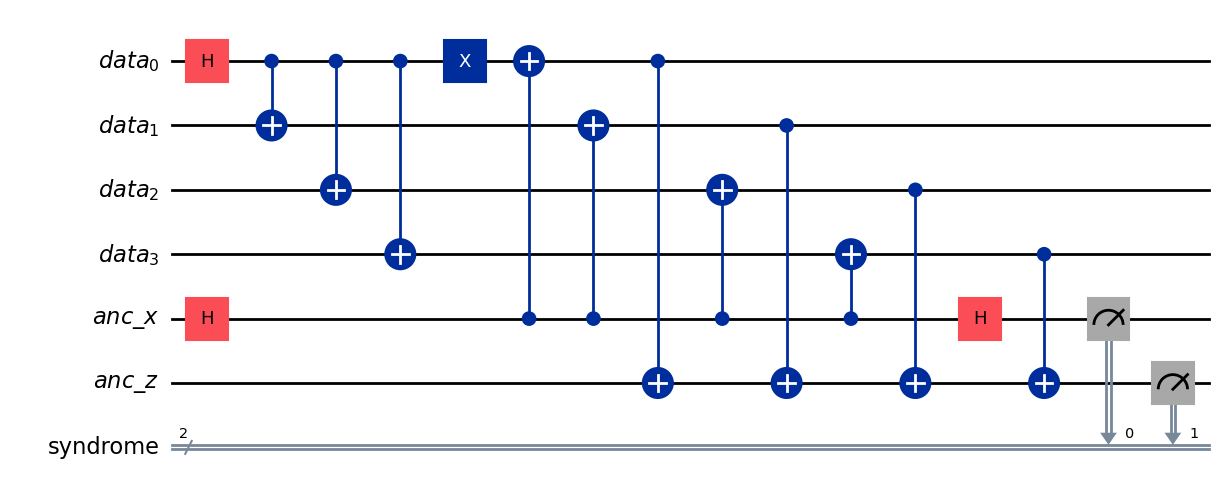

In [4]:
def build_css_syndrome_circuit(error=None,error_qubits=0):
    # four data qubits ,two syndrome ancillas and two classical bits :X-type and Z-type syndrome
    data=QuantumRegister(4,"data")
    anc_x=QuantumRegister(1,"anc_x")
    anc_z=QuantumRegister(1,"anc_z")
    syndrome=ClassicalRegister(2,"syndrome")

    qc=QuantumCircuit(data,anc_x,anc_z,syndrome)

    # Prepare CSS code state
    prepare_css_state(qc,data)

    # Explicitlly inject pauli  error,if requested
    if error=="X":
        qc.x(data[error_qubits])
    elif error=="Z":
        qc.z(data[error_qubits])
    elif error=="Y":
        qc.y(data[error_qubits])

    #mesaure  XXXX using ancilla in |+>
    qc.h(anc_x[0])
    for q in data:
        qc.cx(anc_x[0],q)
    qc.h(anc_x[0])
    qc.measure(anc_x[0],syndrome[0])            

    #measure the ZZZZ using ancilla in |0>
    for q in data:
        qc.cx(q,anc_z[0])
    qc.measure(anc_z[0],syndrome[1])

    return qc
display(build_css_syndrome_circuit("X").draw("mpl"))

        

## Simulate different error scenerios
We now compare self four cases:
- case 1 : No Error
- case 2 : An X error on data qubit 0
- case 3 : An Z error on data qubit 0
- case 4 : An Y error on data qubit 0

oly one error is injected at a time.the simlator execute each circuit repeatedly to estimate the syndrome distribution.The classical register store the x-type syndrome in bit 0 and z-tpe syndrome in bit 1.qiskit display two bit measurement  string in reverse classical bit order .so the displayed string are read as $s_Zs_X$

In [7]:
scenarios={
    "No Error":None,
    "X Error":"X",
    "Z Error":"Z",
    "Y Error":"Y"
}
counts_by_scenario={}
for name,error in scenarios.items():
    circuit=build_css_syndrome_circuit(error=error)
    result=simulator.run(circuit,shots=SHOTS).result()
    counts_by_scenario[name]=result.get_counts()
for name,counts in counts_by_scenario.items():
    print(f"{name:10s}:{counts}")

No Error  :{'00': 4096}
X Error   :{'10': 4096}
Z Error   :{'01': 4096}
Y Error   :{'11': 4096}


## Interprete Syndrome Result
The expecetd dominant syndrome outcomes are:
| Scenarios | $s_X$ | $s_Z$ | Displayed bits |
|---|---:|---:|---:|
| No Error | 0 | 0 | '00' |
| X Error | 0 | 1 | '10' |
| Z Error | 1 | 0 | '01' |
| Y Error | 1 | 1 | '11' |

The syndrome identifies the error type ,not its location for example, an X-erro on any one of the four data qubit produce the same syndrome for these two satibilizers. this limitation is the property of code not the simulation failures.

## Visualization
 

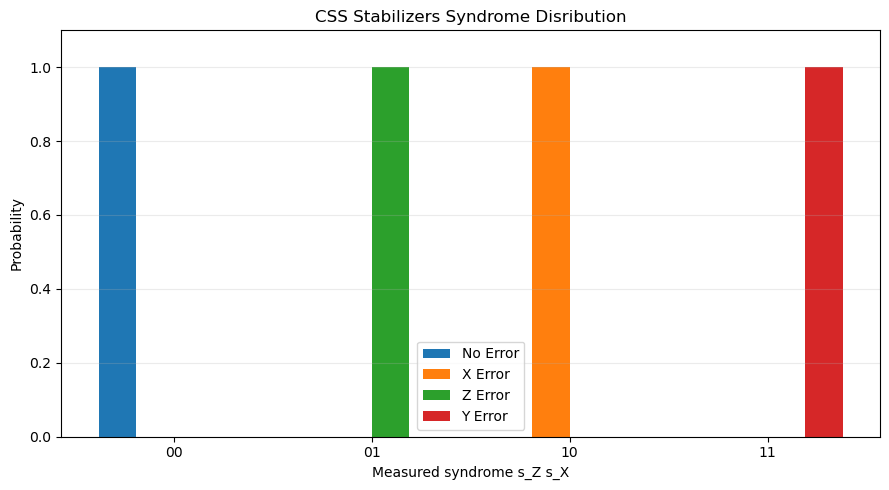

In [9]:
syndrome_labels=["00","01","10","11"]
scenarios_name=list(scenarios.keys())
probabilities=[]
for name in scenarios_name:
    counts=counts_by_scenario[name]
    probabilities.append([counts.get(label,0)/SHOTS
    for label in syndrome_labels])

probabilities=np.array(probabilities)

fig,ax=plt.subplots(figsize=(9,5))
x = np.arange(len(syndrome_labels))
width=0.19

for i,name in  enumerate(scenarios_name):
    ax.bar(
        x+(i-1.5)*width, 
        probabilities[i],
        width,
        label=name 
        )
ax.set_xticks(x)
ax.set_xticklabels(syndrome_labels)
ax.set_xlabel("Measured syndrome s_Z s_X")
ax.set_ylabel("Probability")
ax.set_title("CSS Stabilizers Syndrome Disribution")
ax.set_ylim(0,1.1)
ax.legend()
ax.grid(axis="y",alpha=0.25)
plt.tight_layout()
plt.show()

## Verify the Syndrome behaviour for every data -Qubit location
A useful CSS-code property is that stabilizers response depends on the errors type,even though these two stabilizers cannot distinguish all error locations.
we test X,Z and  errors  on each of four data qubit .the expectec syndrome should remain consistent across location for a fixed error type.

In [10]:
## verify all single qubit locations
for error in ["X","Z","Y"]:
    for qubit in range(4):
        circuit=build_css_syndrome_circuit(error=error,error_qubits=qubit)
        counts=simulator.run(circuit,shots=SHOTS).result().get_counts()
        most_common=max(counts,key=counts.get)
        print(
            f"{error} on data{qubit}"
            f"=> syndrome{most_common}"
        )

X on data0=> syndrome10
X on data1=> syndrome10
X on data2=> syndrome10
X on data3=> syndrome10
Z on data0=> syndrome01
Z on data1=> syndrome01
Z on data2=> syndrome01
Z on data3=> syndrome01
Y on data0=> syndrome11
Y on data1=> syndrome11
Y on data2=> syndrome11
Y on data3=> syndrome11


## Conclusion
The CSS code construction combines x-type and Z-type stabilizers to different classes of quantum error within a single framework.in this notebook , we studied four qubit [4,2,2] CSS code ,whose stabilizers are XXXX and ZZZZ.
using Qiskit,we prepared a code state ,injected X,Y and Z errors and extracted both stabilizers syndrome using ancilla qubits .the measured distribution demonstrate how syndrome changes according to error type. 

the visualization confirms the expected error detection behavior in an ideal simulation however this code does not correct arbitary single qubit because its syndrome information is insufficient to identify every error location.


---

**Author:** *Shreya Palase*  

**Date Created:**  *28-sep-2026*

**project:** Quantum-Error-Correction-Techniques

**File:** Day06-CSS_Code_full.ipynb

Thank you and Keep Learning!

<sub>© Shreya Palase- All Rights Reserved.This notebook is part of a structured learning series designed for Github publication.</sub>